# Function 3 - Week 10: Model predictions

Use **24 official observations through round 9** to compare models for the next query. The [week-level report](../report.md) connects the new fits to the measured return.

The neural comparison retains three architectures and seeds 11, 42 and 73. Fitted scalers use training rows inside each leave-one-out fold. The candidate scores are provisional.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

repository_dir = next(folder for folder in Path.cwd().parents if (folder / "run-python.ps1").is_file())
expected_interpreter = repository_dir / ".venv" / "Scripts" / "python.exe"
if Path(sys.executable).resolve() != expected_interpreter.resolve():
    raise RuntimeError(f"Select the capstone-local kernel: {expected_interpreter}")
shared_dir = repository_dir / "stage-2-bbo/notebooks/Shared"
for folder in (shared_dir, shared_dir.parent / "Function_1/FunctionSpecificShared"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from exploration_review_helpers import load_exploration_review
from cohort_review_helpers import load_cohort_review
from model_helpers import make_models
from model_review_helpers import make_regression_models, review_latest_predictions, noise_sensitivity
from model_review_plots import plot_held_out_comparison
from surrogate_study_helpers import make_study_models, evaluate_regressors
from prediction_review_helpers import (
    select_gp, paired_peer_review, choose_training_scope, neural_architecture_review,
    make_candidate_review, review_gp_query, neural_candidate_review, neural_gradient_review,
)
from prediction_review_plots import plot_response_profiles, plot_score_planes
from neural_explorer import save_neural_explorer, network_prediction, gp_prediction
from function_1_model_helpers import signed_log
from query_budget import remaining_queries
print("Python interpreter:", sys.executable)


Python interpreter: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Declare settings before fitting; the existing Week 10 observation snapshot is immutable.
FUNCTION_NUMBER = 3
CURRENT_WEEK = 10
INPUT_COLUMNS = ['x1', 'x2', 'x3']
EXPECTED_ROUND_COUNTS = {0: 15, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent if ANALYSIS_DIR.name == "official" else ANALYSIS_DIR
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
COHORT_PATH = WEEK_DIR / "cohort/observations.csv" if FUNCTION_NUMBER <= 4 else None
COHORT_AUDIT_PATH = WEEK_DIR / "cohort/data-audit.json"
EXPECTED_PEERS = 5
TITLE = f"Function {FUNCTION_NUMBER} - Week 10"
HEIGHT_SCALE = None
TARGET_LABEL = 'output y'
SELECTION_METRIC = 'LOO RMSE'
MODEL_SETTINGS = {'noise_fraction': 0.1, 'ridge_alpha': 1.0, 'kernel_ridge_alpha': 0.1, 'kernel_ridge_gamma': 1.0, 'polynomial_degree': 2, 'polynomial_ridge_alpha': 1.0, 'length_scale': 0.3, 'length_scale_bounds': (0.03, 2.0), 'amplitude': 1.0, 'amplitude_bounds': (0.01, 100.0), 'optimiser_restarts': 3, 'seed': 42}
FIXED_MODEL_SETTINGS = None
FEATURE_SETS = {}
MODEL_NAMES = ['Mean baseline', 'Linear regression', 'Ridge', 'Kernel ridge', 'Quadratic ridge', 'Gaussian process', 'GP: separate length scales']
GP_NAMES = ['Gaussian process', 'GP: separate length scales']
ARCHITECTURES = [
    {"name": "tanh-8", "layers": [8], "activation": "tanh"},
    {"name": "tanh-16", "layers": [16], "activation": "tanh"},
    {"name": "relu-8-8", "layers": [8, 8], "activation": "relu"},
]
SEEDS = [11, 42, 73]
NEURAL_SETTINGS = dict(alpha=.1, max_iter=400, max_fun=15000, tolerance=1e-6, gp_restarts=3)
EXPLORATION_WEIGHT = 1.96
EXPLORATION_WEIGHTS = (0., 1., 1.96, 3.)
MIN_QUERY_DISTANCE = 0.0
SEARCH_SETTINGS = dict(broad_power=14, broad_seed=42, local_power=12, local_seed=43,
                       local_radius=.15, precision=6, include_corners=True)

SAVED_FOLLOW_UP = [0.495, 0.55, 0.45]

In [3]:
review = load_exploration_review(DATA_PATH, input_columns=INPUT_COLUMNS,
                                       expected_round_counts=EXPECTED_ROUND_COUNTS)
data = review["data"]
inputs, raw_y = review["inputs"].to_numpy(), review["outputs"].to_numpy()
target = signed_log(raw_y, scale=HEIGHT_SCALE) if FUNCTION_NUMBER == 1 else raw_y.copy()
anchor = inputs[int(np.argmax(raw_y))].copy()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
peer_review = None
if COHORT_PATH is not None:
    audit = json.loads(COHORT_AUDIT_PATH.read_text(encoding="utf-8"))
    if hashlib.sha256(COHORT_PATH.read_bytes()).hexdigest() != audit["cohort_csv_sha256"]:
        raise ValueError("Retained peer snapshot hash mismatch")
    peer_review = load_cohort_review(COHORT_PATH, DATA_PATH, input_columns=INPUT_COLUMNS,
        expected_round_counts=EXPECTED_ROUND_COUNTS, expected_peer_count=EXPECTED_PEERS)
    peers = peer_review["data"].loc[peer_review["peer_mask"]]
    peer_inputs = peers[INPUT_COLUMNS].to_numpy()
    peer_raw = peers.y.to_numpy()
    peer_target = signed_log(peer_raw, scale=HEIGHT_SCALE) if FUNCTION_NUMBER == 1 else peer_raw
    known_inputs = peer_review["inputs"].to_numpy()
else:
    peer_inputs = np.empty((0, len(INPUT_COLUMNS)))
    peer_target = np.empty(0)
    known_inputs = inputs
display(pd.Series({"Official rows": len(data), "Retained peer rows": len(peer_inputs),
                   "Target units": TARGET_LABEL, "Query opportunities including Week 10": remaining_queries(WEEK_DIR)}))


Official rows                                  24
Retained peer rows                              5
Target units                             output y
Query opportunities including Week 10           4
dtype: object

### Fit the declared models

Leave-one-out errors compare like-for-like targets. Every estimator is refitted inside each fold; warnings remain in the saved review. The next-query policy selects among the declared GPs, retaining uncertainty-aware acquisition while testing neural predictive usefulness.

In [4]:
# Preserve each function's established families; add the declared neural comparators.
if FUNCTION_NUMBER == 1:
    models = make_models(**FIXED_MODEL_SETTINGS)
    adaptive = make_regression_models(len(INPUT_COLUMNS), **MODEL_SETTINGS)
    models.update({name: adaptive[name] for name in ["Gaussian process", "GP: separate length scales"]})
else:
    available = make_regression_models(len(INPUT_COLUMNS), feature_sets=FEATURE_SETS, **MODEL_SETTINGS)
    models = {name: available[name] for name in MODEL_NAMES}
if FUNCTION_NUMBER == 5:
    if not (raw_y > 0).all():
        raise ValueError("The existing log-target comparator needs positive observations")
    models["GP with log target (median)"] = TransformedTargetRegressor(
        regressor=clone(models["Gaussian process"]), func=np.log, inverse_func=np.exp)
neural_models, _, neural_metadata = make_study_models(len(INPUT_COLUMNS),
    architectures=ARCHITECTURES, seeds=SEEDS, **NEURAL_SETTINGS)
models.update({name: neural_models[name] for name in neural_metadata})
run = evaluate_regressors(models, inputs, target)
official_gp = select_gp(run, GP_NAMES, metric=SELECTION_METRIC)
networks = neural_architecture_review(run, neural_metadata, metric=SELECTION_METRIC)
display(run["table"].sort_values(SELECTION_METRIC).round(6))
display(networks["table"].round(6))


Regression complete: Mean baseline; warnings=0


Regression complete: Linear regression; warnings=0


Regression complete: Ridge; warnings=0


Regression complete: Kernel ridge; warnings=0


Regression complete: Quadratic ridge; warnings=0


Regression complete: Gaussian process; warnings=0


... (8 outputs left out)

Regression complete: NN relu-8-8 seed 42; warnings=17


Regression complete: NN relu-8-8 seed 73; warnings=6


,Model,LOO RMSE,LOO MAE,Rank correlation,Training RMSE,Fit warnings,RMSE / baseline
0,GP: separate length scales,0.068247,0.031884,0.789565,0.003098,27,0.884091
1,Mean baseline,0.077195,0.047177,-1.000000,0.073978,0,1.000000
2,Gaussian process,0.080184,0.048386,0.243478,0.001156,0,1.038723
3,Ridge,0.082216,0.052211,-0.299130,0.069233,0,1.065042
4,Kernel ridge,0.084685,0.058394,-0.003478,0.044191,0,1.097028
5,NN relu-8-8 seed 73,0.086225,0.059500,0.385217,0.014790,6,1.116978
6,Linear regression,0.088647,0.059345,-0.262609,0.068699,0,1.148355
7,Quadratic ridge,0.095499,0.067971,-0.040000,0.051181,0,1.237121
8,NN tanh-16 seed 42,0.100240,0.063503,0.270435,0.011169,25,1.298532
9,NN tanh-16 seed 11,0.103262,0.065643,0.268696,0.012761,22,1.337680


,architecture,mean,std,min,max
0,tanh-16,0.102875,0.002464,0.100240,0.105122
1,tanh-8,0.106966,0.001829,0.105372,0.108962
2,relu-8-8,0.112212,0.022713,0.086225,0.128268


### Compare official and retained-peer training

Peer-assisted fits hold out each official row and add only the previously audited peer rows to its training set. Compare both scopes on the same official targets; peer outputs do not change official progress or query allowance. Ties retain official-only training.

In [5]:
peer_run = None
if peer_review is not None:
    peer_run = paired_peer_review({name: models[name] for name in GP_NAMES}, inputs,
        peer_inputs, target, peer_target, run)
    display(peer_run["table"].round(6))
selected = choose_training_scope(run, GP_NAMES, peer_run=peer_run, metric=SELECTION_METRIC)
selected_model = selected["model"]
fit_inputs = known_inputs if selected["scope"] == "official_plus_retained_peers" else inputs
selected_predictions = (peer_run["predictions"][selected["name"]]
                        if selected["scope"] == "official_plus_retained_peers" else run["predictions"][selected["name"]])
neural_metrics = {"LOO RMSE": root_mean_squared_error(target, networks["predictions"]),
                  "LOO MAE": mean_absolute_error(target, networks["predictions"])}
display(pd.Series({"Selected GP": selected["name"], "Training scope": selected["scope"],
    "Selection metric": SELECTION_METRIC, "Selected GP official-target error": selected["error"],
    "Neural architecture": networks["architecture"], "Neural seed-mean official-target error": neural_metrics[SELECTION_METRIC]}))


Peer-assisted official-target review complete: Gaussian process


Peer-assisted official-target review complete: GP: separate length scales


,Model,Official LOO RMSE,Peer-assisted LOO RMSE,Official LOO MAE,Peer-assisted LOO MAE,Fit warnings
0,Gaussian process,0.080184,0.044691,0.048386,0.035205,0
1,GP: separate length scales,0.068247,0.051564,0.031884,0.035604,8


Selected GP                                           Gaussian process
Training scope                            official_plus_retained_peers
Selection metric                                              LOO RMSE
Selected GP official-target error                             0.044691
Neural architecture                                            tanh-16
Neural seed-mean official-target error                        0.102501
dtype: object

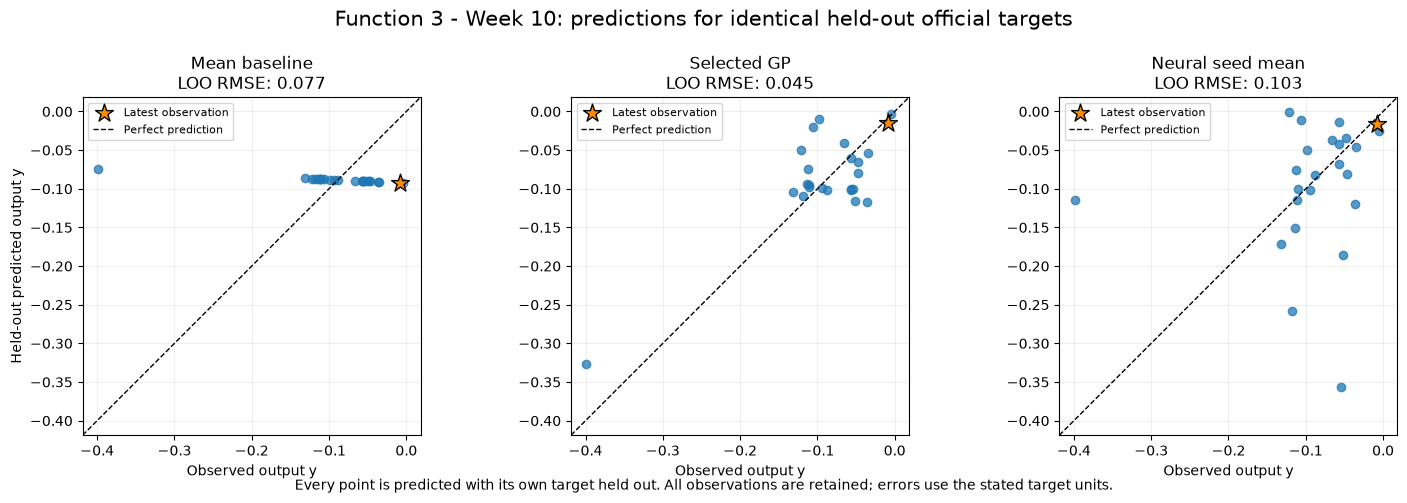

,Model,Latest held-out prediction,Latest error,Latest absolute error (%),Latest share of squared error (%),Other rows LOO RMSE
0,Selected GP,-0.014328,-0.006219,76.688790,0.080684,0.045634
1,Neural seed mean,-0.016412,-0.008302,102.381586,0.027337,0.104691


In [6]:
display(plot_held_out_comparison(
    {"Mean baseline": run["predictions"]["Mean baseline"],
     "Selected GP": selected_predictions, "Neural seed mean": networks["predictions"]},
    target, model_names=["Mean baseline", "Selected GP", "Neural seed mean"],
    latest_mask=review["latest_mask"], target_label=TARGET_LABEL,
    title=f"{TITLE}: predictions for identical held-out official targets",
    save_to=FIGURES_DIR / "model-validation.png"))
display(review_latest_predictions({"Selected GP": selected_predictions,
    "Neural seed mean": networks["predictions"]}, target, review["latest_mask"]).round(6))


### Review the next query on a common candidate pool

Retain the seeded broad and incumbent-local candidate searches, six-decimal bounds and duplicate exclusions. The geometric comparator is the farthest eligible point in this frozen pool; it is a finite-pool coverage proxy. Neural alternatives maximise mean predictions across seeds. GP UCB uses latent posterior SD. Neither score is a new function evaluation.

In [7]:
candidates, coverage_point = make_candidate_review(inputs, anchor,
    input_columns=INPUT_COLUMNS, search_settings=SEARCH_SETTINGS,
    minimum_distance=MIN_QUERY_DISTANCE, excluded_inputs=known_inputs)
query_run = review_gp_query(selected, candidates, known_inputs, target,
    input_columns=INPUT_COLUMNS, weights=EXPLORATION_WEIGHTS, weight=EXPLORATION_WEIGHT,
    feature_sets=FEATURE_SETS, minimum_distance=MIN_QUERY_DISTANCE, training_inputs=fit_inputs)
proposal, scored = query_run["proposal"], query_run["scores"]
next_query = np.asarray(proposal["point"])
neural_proposal = neural_candidate_review(networks, candidates, input_columns=INPUT_COLUMNS)
display(pd.Series(proposal))
display(pd.Series(neural_proposal))
display(scored.head(5)[[*INPUT_COLUMNS, "posterior_mean", "posterior_sd", "ucb", "candidate_source", "nearest_observed_distance"]])


point                         [0.385408, 0.658043, 0.480703]
predicted_output                                   -0.032751
posterior_std                                        0.06093
ucb                                                 0.086671
predicted_mean_improvement                         -0.027799
inside_sampled_hull                                     True
portal_input                      0.385408-0.658043-0.480703
nearest_observed_distance                            0.14617
dtype: object

point                                     [0.993754, 0.566053, 0.64151]
predicted_target                                               0.012587
seed_prediction_sd                                             0.017631
architecture                                                    tanh-16
portal_input                                 0.993754-0.566053-0.641510
criterion             mean prediction across all declared seeds; not...
dtype: object

,x1,x2,x3,posterior_mean,posterior_sd,ucb,candidate_source,nearest_observed_distance
0,0.385408,0.658043,0.480703,-0.032751,0.060930,0.086671,Near incumbent,0.146170
1,0.389641,0.653677,0.486322,-0.032062,0.060493,0.086505,Near incumbent,0.142199
2,0.372808,0.654556,0.488263,-0.039061,0.063905,0.086193,Near incumbent,0.158476
3,0.375786,0.625030,0.483038,-0.036166,0.062425,0.086187,Near incumbent,0.148711
4,0.379414,0.629050,0.470074,-0.032448,0.060468,0.086070,Near incumbent,0.143284


In [8]:
# Use the same frozen pool and mean/SD values for every exploration weight.
display(query_run["weight_sensitivity"].round(6))
scope_proposals = {"selected": {"scope": selected["scope"], "model": selected["name"], **proposal}}
if peer_run is not None:
    alternative = (dict(official_gp, scope="official") if selected["scope"] != "official" else
                   choose_training_scope(run, GP_NAMES, peer_run=peer_run, metric=SELECTION_METRIC))
    # If the official fit won, still record the best peer-assisted GP's common-pool alternative.
    if selected["scope"] == "official":
        col = "Peer-assisted " + SELECTION_METRIC
        peer_name = peer_run["table"].set_index("Model")[col].idxmin()
        alternative = dict(name=peer_name, model=peer_run["fitted"][peer_name], scope="official_plus_retained_peers")
    alternative_inputs = known_inputs if alternative["scope"] != "official" else inputs
    alt = review_gp_query(alternative, candidates, known_inputs, target, input_columns=INPUT_COLUMNS,
        weights=EXPLORATION_WEIGHTS, weight=EXPLORATION_WEIGHT, feature_sets=FEATURE_SETS,
        minimum_distance=MIN_QUERY_DISTANCE, training_inputs=alternative_inputs)
    scope_proposals["alternative"] = {"scope": alternative["scope"], "model": alternative["name"], **alt["proposal"]}
    display(pd.DataFrame(scope_proposals).T)
regularisation_review = None
if FUNCTION_NUMBER in (2, 5, 6, 7, 8):
    training_target = np.r_[target, peer_target] if selected["scope"] != "official" else target
    regularisation_review = noise_sensitivity(selected_model, fit_inputs, training_target, next_query,
        fractions=(.03, .10, .30), fitted_noise_fraction=.10)
    display(regularisation_review.rename(columns={"Assumed noise fraction": "GP regularisation fraction"}).round(6))
if FUNCTION_NUMBER == 5:
    from scipy.spatial.distance import cdist
    all_candidates, _ = make_candidate_review(inputs, anchor, input_columns=INPUT_COLUMNS,
        search_settings=SEARCH_SETTINGS, minimum_distance=0.)
    from model_review_helpers import score_review_candidates
    spacing_scores = score_review_candidates(selected_model, all_candidates,
        input_columns=INPUT_COLUMNS, weight=EXPLORATION_WEIGHT)
    spacing_rows = []
    for minimum in (0., .01, .02, .05):
        top = spacing_scores.loc[spacing_scores.nearest_observed_distance >= minimum].iloc[0]
        spacing_rows.append({"Minimum distance": minimum,
            "Portal input": "-".join(f"{top[c]:.6f}" for c in INPUT_COLUMNS),
            "Nearest observed distance": top.nearest_observed_distance,
            "Predicted target": top.posterior_mean, "UCB": top.ucb})
    spacing_review = pd.DataFrame(spacing_rows)
    display(spacing_review)


,Weight,x1,x2,x3,Predicted output,Posterior SD
0,0.00,0.501047,0.629237,0.441145,-0.001498,0.014303
1,1.00,0.430166,0.654337,0.458562,-0.012768,0.046097
2,1.96,0.385408,0.658043,0.480703,-0.032751,0.060930
3,3.00,0.357146,0.651977,0.508323,-0.049569,0.067782


,scope,model,point,predicted_output,posterior_std,ucb,predicted_mean_improvement,inside_sampled_hull,portal_input,nearest_observed_distance
selected,official_plus_retained_peers,Gaussian process,"[0.385408, 0.658043, 0.480703]",-0.032751,0.06093,0.086671,-0.027799,True,0.385408-0.658043-0.480703,0.14617
alternative,official,GP: separate length scales,"[0.152252, 0.992806, 0.410288]",0.031367,0.037759,0.105375,0.036319,False,0.152252-0.992806-0.410288,0.244663


### Inspect conditional responses and neural input gradients

Every omitted coordinate is held fixed. Only measurements actually on a slice are plotted on its curve. The GP band and neural seed band describe different quantities. Input gradients are checked against finite differences and describe a fitted model, not causal effects.

At a near-zero ReLU activation, central differences may cross a kink. Such anchor checks are marked explicitly; implementation checks then use a declared nearby smooth probe. The anchor derivative is not presented as validated.

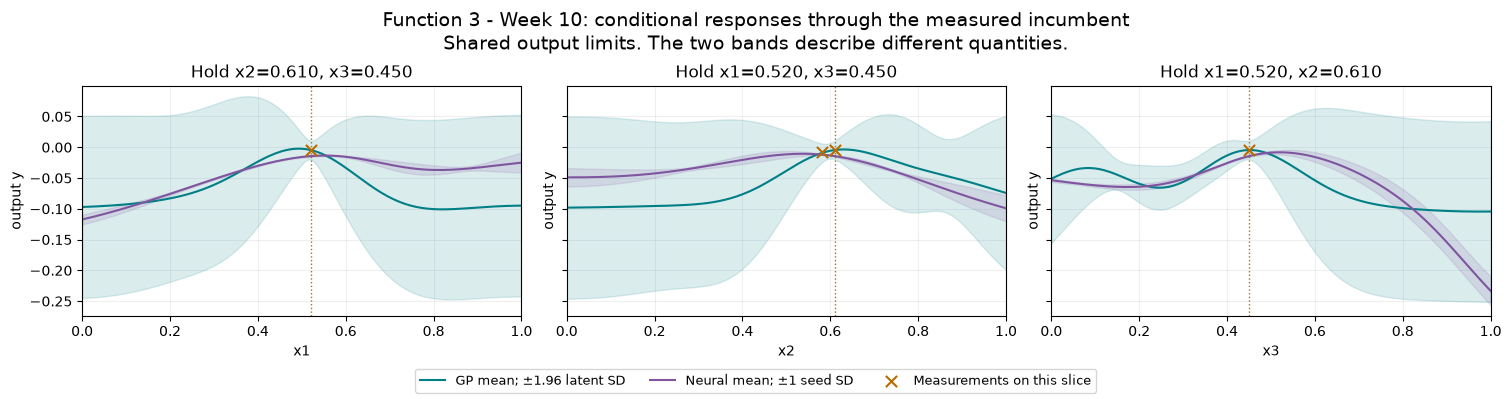

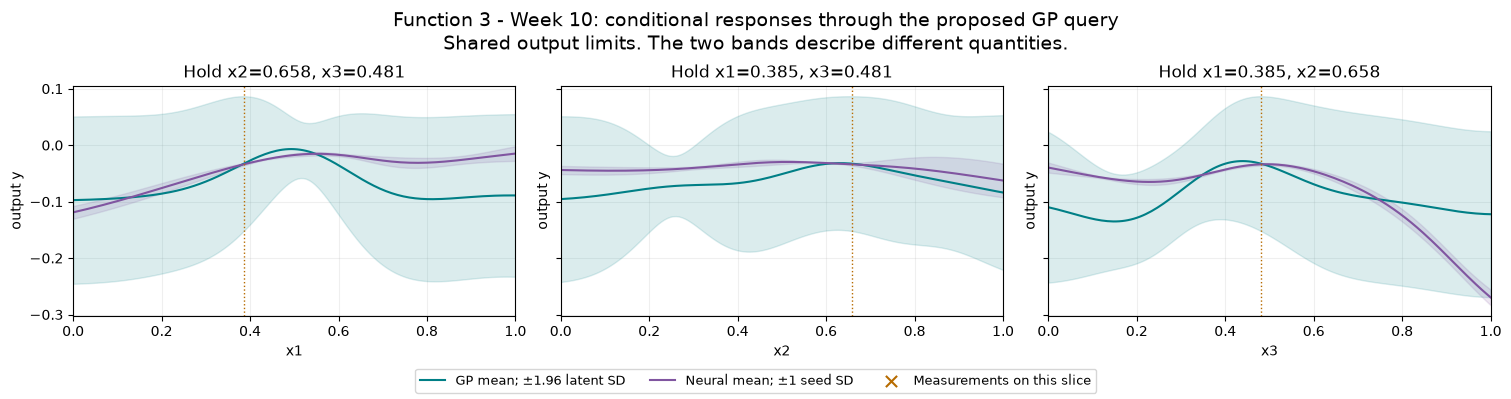

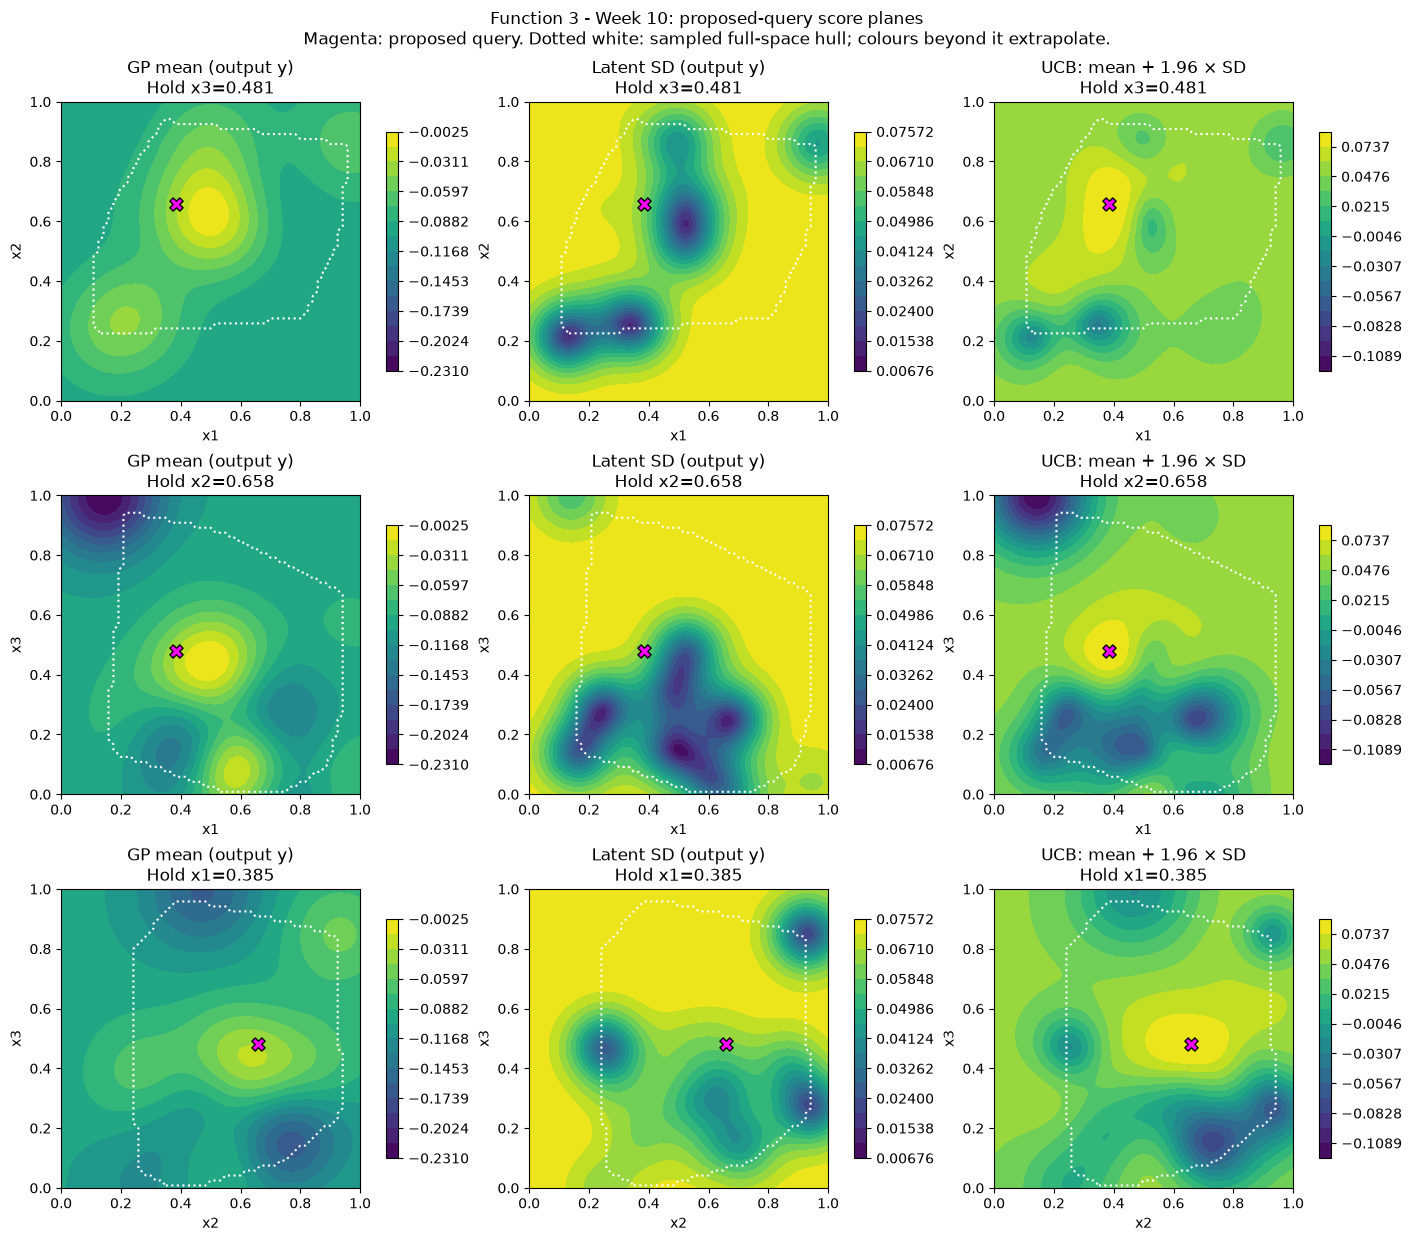

,Model,maximum_relative_error,passes,check_location,check_point,anchor_relative_error,anchor_check_passes
0,NN tanh-16 seed 11,2.982306e-10,True,anchor,"[0.52, 0.61, 0.45]",2.982306e-10,True
1,NN tanh-16 seed 42,3.213276e-10,True,anchor,"[0.52, 0.61, 0.45]",3.213276e-10,True
2,NN tanh-16 seed 73,2.618685e-10,True,anchor,"[0.52, 0.61, 0.45]",2.618685e-10,True


,x1,x2,x3
Model,,,
NN tanh-16 seed 11,0.049439,-0.160517,0.158011
NN tanh-16 seed 42,0.057742,-0.049915,0.194665
NN tanh-16 seed 73,0.053050,-0.106516,0.173938


In [9]:
display(plot_response_profiles(selected_model, networks["models"], inputs, target, anchor,
    input_columns=INPUT_COLUMNS, target_label=TARGET_LABEL,
    title=f"{TITLE}: conditional responses through the measured incumbent",
    save_to=FIGURES_DIR / "model-response-incumbent.png"))
display(plot_response_profiles(selected_model, networks["models"], inputs, target, next_query,
    input_columns=INPUT_COLUMNS, target_label=TARGET_LABEL,
    title=f"{TITLE}: conditional responses through the proposed GP query",
    save_to=FIGURES_DIR / "model-response-proposal.png"))
if len(INPUT_COLUMNS) <= 3:
    display(plot_score_planes(selected_model, fit_inputs, next_query, input_columns=INPUT_COLUMNS,
        target_label=TARGET_LABEL, title=f"{TITLE}: proposed-query score planes",
        weight=EXPLORATION_WEIGHT, save_to=FIGURES_DIR / "model-query-planes.png"))
gradient_review = neural_gradient_review(networks, anchor)
display(gradient_review.drop(columns="gradient"))
if not gradient_review.passes.all():
    raise ValueError("A neural input-gradient parity check failed; inspect before interpreting it")
display(pd.DataFrame([row for row in gradient_review.gradient], columns=INPUT_COLUMNS,
                     index=gradient_review.Model))


### Interactive GP and neural input explorer

[Open the offline explorer](figures/neural-network-explorer.html). Change any input, choose a neural architecture, compare its three seeds with the GP, or reset to the measured incumbent or proposed query. Curves update from exported fitted weights. This tool performs no training, course evaluations or submissions.

In [10]:
gp_error = f"{selected['error']:.6g}"
validation_text = (f"Selected GP {SELECTION_METRIC} on official targets: {gp_error}. "
    f"Neural seed-mean {SELECTION_METRIC}: {neural_metrics[SELECTION_METRIC]:.6g}. "
    f"Network architecture selected by average error across seeds {SEEDS}.")
explorer = save_neural_explorer(FIGURES_DIR / "neural-network-explorer.html",
    models=run["fitted"], metadata=neural_metadata, selected_architecture=networks["architecture"],
    gp=selected_model, input_columns=INPUT_COLUMNS, anchor=anchor, proposal=next_query,
    title=f"{TITLE}: GP and neural input explorer", target_label=TARGET_LABEL,
    scope=selected["scope"], validation=validation_text)
# Check exported forward passes at observations, new proposals and domain boundaries.
test_points = np.vstack([inputs, next_query, np.zeros(len(INPUT_COLUMNS)), np.full(len(INPUT_COLUMNS), .999999)])
for architecture, specs in explorer["networks"].items():
    for spec in specs:
        name = next(name for name, settings in neural_metadata.items()
                    if settings["architecture"] == architecture and settings["seed"] == spec["seed"])
        np.testing.assert_allclose(network_prediction(spec, test_points), run["fitted"][name].predict(test_points), rtol=1e-10, atol=1e-9)
expected_mean, expected_sd = selected_model.predict(test_points, return_std=True)
actual_mean, actual_sd = gp_prediction(explorer["gp"], test_points)
np.testing.assert_allclose(actual_mean, expected_mean, rtol=1e-10, atol=1e-9)
np.testing.assert_allclose(actual_sd, expected_sd, rtol=1e-9, atol=1e-9)
print("Exported GP/neural predictions match the fitted Python models.")


Exported GP/neural predictions match the fitted Python models.


In [11]:
magnitude_review = None
if FUNCTION_NUMBER == 1:
    # Fit a separate activity explanation; it cannot choose the signed-score proposal.
    magnitude_models = {"Mean baseline": models["Mean baseline"], **{name: models[name] for name in GP_NAMES}}
    magnitude_review = evaluate_regressors(magnitude_models, inputs, np.abs(target))
    display(magnitude_review["table"].sort_values(SELECTION_METRIC).round(6))
    print("Magnitude explains activity only. The proposed query above maximises signed-score GP UCB.")


### Re-score the saved follow-up

This point was carried forward from the earlier lookahead. The table evaluates it with the refreshed weekly fits and shows its distance from the available observations.

In [12]:
# Re-score the previous lookahead's possible follow-up with the new weekly fits.
follow_up_point = np.asarray(SAVED_FOLLOW_UP, dtype=float)
if (follow_up_point.shape != (len(INPUT_COLUMNS),) or not np.isfinite(follow_up_point).all()
        or np.any(follow_up_point < 0) or np.any(follow_up_point >= 1)
        or not np.array_equal(follow_up_point, follow_up_point.round(6))):
    raise ValueError("The saved follow-up must be a valid six-decimal portal input.")
mean, sd = selected_model.predict(follow_up_point[None], return_std=True)
neural_at_follow_up = np.array([model.predict(follow_up_point[None])[0] for model in networks["models"]])
distance = float(np.linalg.norm(known_inputs - follow_up_point, axis=1).min())
follow_up = dict(
    portal_input="-".join(f"{value:.6f}" for value in follow_up_point), point=follow_up_point.tolist(),
    gp_mean=float(mean[0]), gp_latent_sd=float(sd[0]), gp_ucb=float(mean[0] + EXPLORATION_WEIGHT * sd[0]),
    neural_mean=float(neural_at_follow_up.mean()), neural_seed_sd=float(neural_at_follow_up.std(ddof=1)),
    nearest_known_input_distance=distance, eligible=bool(distance > 0 and distance >= MIN_QUERY_DISTANCE),
    target_units=TARGET_LABEL, gp_training_scope=selected["scope"],
)
display(pd.Series(follow_up))


portal_input                      0.495000-0.550000-0.450000
point                                    [0.495, 0.55, 0.45]
gp_mean                                            -0.016522
gp_latent_sd                                        0.020987
gp_ucb                                              0.024613
neural_mean                                        -0.012892
neural_seed_sd                                      0.003117
nearest_known_input_distance                        0.039051
eligible                                                True
target_units                                        output y
gp_training_scope               official_plus_retained_peers
dtype: object

### Save a provisional proposal

Four query opportunities remain, including Week 10. The held-out estimates are retrospective and use the same official targets across models.

In [13]:
selected_gp = selected_model.steps[-1][1] if hasattr(selected_model, "steps") else selected_model
summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "analysis": "week_10_model_review",
    "observations": len(inputs), "official_observations": len(inputs), "retained_peer_observations": len(peer_inputs),
    "python_executable": sys.executable, "target_units": TARGET_LABEL, "height_scale": HEIGHT_SCALE,
    "best_observed_raw_output": float(raw_y.max()), "best_observed_target": float(target.max()),
    "query_model": selected["name"], "training_scope": selected["scope"],
    "selection_metric": SELECTION_METRIC, "official_target_error": selected["error"],
    "baseline_error": float(run["table"].set_index("Model").loc["Mean baseline", SELECTION_METRIC]),
    "proposal_status": "proposed_not_submitted", "remaining_queries": remaining_queries(WEEK_DIR),
    "portal_input": proposal["portal_input"], "point": proposal["point"], "proposal": proposal,
    "proposal_target_units": TARGET_LABEL, "ucb_weight": EXPLORATION_WEIGHT,
    "candidate_count": len(candidates), "minimum_query_distance": MIN_QUERY_DISTANCE,
    "coverage_proxy_point": coverage_point.tolist(), "search_settings": SEARCH_SETTINGS,
    "fitted_kernel": str(selected_gp.kernel_), "model_settings": MODEL_SETTINGS,
    "model_comparison": run["table"].to_dict(orient="records"),
    "model_warnings": run["warnings"], "held_out_predictions": {k: v.tolist() for k,v in run["predictions"].items()},
    "peer_comparison": None if peer_run is None else peer_run["table"].to_dict(orient="records"),
    "peer_warnings": None if peer_run is None else peer_run["warnings"],
    "scope_proposals": scope_proposals, "weight_sensitivity": query_run["weight_sensitivity"].to_dict(orient="records"),
    "regularisation_sensitivity": None if regularisation_review is None else regularisation_review.to_dict(orient="records"),
    "neural_architectures": ARCHITECTURES, "neural_seeds": SEEDS, "neural_settings": NEURAL_SETTINGS,
    "neural_architecture_comparison": networks["table"].to_dict(orient="records"),
    "selected_neural_architecture": networks["architecture"], "neural_ensemble_errors": neural_metrics,
    "saved_follow_up": follow_up,
    "neural_proposal": neural_proposal, "neural_gradient_checks": gradient_review.to_dict(orient="records"),
    "magnitude_comparison": None if magnitude_review is None else magnitude_review["table"].to_dict(orient="records"),
    "snapshot_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "cohort_audit_sha256": None if COHORT_PATH is None else hashlib.sha256(COHORT_AUDIT_PATH.read_bytes()).hexdigest(),
}
if FUNCTION_NUMBER == 5:
    summary["spacing_sensitivity"] = spacing_review.to_dict(orient="records")
text = json.dumps(summary, indent=2, allow_nan=False)
(ANALYSIS_DIR / "model-review.json").write_text(text + "\n", encoding="utf-8")
print(text)


{
  "function": 3,
  "week": 10,
  "analysis": "week_10_model_review",
  "observations": 24,
  "official_observations": 24,
  "retained_peer_observations": 5,
  "python_executable": "C:\\_Source\\Imperial-ML-AI-Live\\Capstone\\imperial-capstone\\.venv\\Scripts\\python.exe",
  "target_units": "output y",
  "height_scale": null,
  "best_observed_raw_output": -0.004952000821836788,
  "best_observed_target": -0.004952000821836788,
  "query_model": "Gaussian process",
  "training_scope": "official_plus_retained_peers",
  "selection_metric": "LOO RMSE",
  "official_target_error": 0.04469088950230575,
  "baseline_error": 0.077194746239121,
  "proposal_status": "proposed_not_submitted",
  "remaining_queries": 4,
  "portal_input": "0.385408-0.658043-0.480703",
  "point": [
    0.385408,
    0.658043,
    0.480703
  ],
  "proposal": {
    "point": [
      0.385408,
      0.658043,
      0.480703
    ],
    "predicted_output": -0.032751212296246224,
    "posterior_std": 0.060929545697577,
    "uc

### Course lifecycle for this review

1. **Define the goal and scope** — give the project owner comparable model evidence for a single provisional Week 10 query.
2. **Gather the data** — use the independent official snapshot and the retained peer rows where they were part of the weekly comparison.
3. **Explore the data** — read the companion measured review for ranks, input patterns and the round 9 forecast check.
4. **Clean and preprocess the data** — validate the snapshots and fit scalers inside each held-out training fold.
5. **Select and engineer features** — use the declared continuous coordinates and feature subsets. Function 1 uses the signed-log target, with a separate magnitude diagnostic.
6. **Define the machine-learning task** — regress the continuous score as a surrogate for bounded black-box maximisation.
7. **Partition the data** — leave one official row out per fold. Peer-assisted GP fits keep the same official validation targets.
8. **Select and train candidate methods** — refit the declared GP, regression and neural comparators with fixed search settings and seeds.
9. **Evaluate and interpret the results** — compare against the mean baseline and review held-out error, score sensitivity and distinct measures of model uncertainty.
10. **Deploy and iterate** — deployment is not applicable to this course review. Save provisional evidence for the next decision and compare it with future feedback.
